<a href="https://colab.research.google.com/github/Ethan-Tse/Problem-Set-4-Econ_3916_PS4.ipynb/blob/main/Problem%20Set%204/Econ_3916_PS4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [2]:
import statsmodels.api as sm

# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others

In [3]:
# Units: floor area in thousand sq ft, foot traffic in thousand visitors a month,
# income in $ thousand, revenue in $ thousand a month.
floor_area    = rng.uniform(2, 40, N_STORES)
foot_traffic  = rng.normal(50, 15, N_STORES).clip(5)
median_income = rng.normal(65, 15, N_STORES)
years_open    = rng.integers(1, 26, N_STORES).astype(float)
junk          = rng.normal(size=(N_STORES, 7))             # 7 columns that have nothing to do with revenue
traffic_area_index = 0.5 * floor_area + 0.3 * foot_traffic + rng.normal(0, 0.4, N_STORES)   # nearly a combination of two others

stores = pd.DataFrame({"floor_area": floor_area, "foot_traffic": foot_traffic, "median_income": median_income,
                       "years_open": years_open, "traffic_area_index": traffic_area_index})
for j in range(7):
    stores[f"junk_{j + 1}"] = junk[:, j]

KINK, SLOPE_AFTER = 22, 0.40
effective_area = np.where(floor_area <= KINK, floor_area, KINK + SLOPE_AFTER * (floor_area - KINK))
true_mean = 150 + 62 * effective_area + 2.5 * foot_traffic + 3.0 * median_income + 5.0 * years_open
noise_sd = 11 + 2.8 * floor_area
revenue = pd.Series(true_mean + rng.normal(0, noise_sd), name="revenue")

print(f"{N_STORES} stores, {stores.shape[1]} predictors: {list(stores.columns)}")
print(f"\nrevenue ($ thousand a month): mean {revenue.mean():,.0f}, sd {revenue.std():,.0f}, "
      f"min {revenue.min():,.0f}, max {revenue.max():,.0f}")
print(f"correlation of traffic_area_index with 0.5*floor_area + 0.3*foot_traffic: "
      f"{np.corrcoef(traffic_area_index, 0.5 * floor_area + 0.3 * foot_traffic)[0, 1]:.4f}")
print(f"noise sd runs from {noise_sd.min():.1f} (smallest store) to {noise_sd.max():.1f} (largest)")
display(stores.describe().loc[["mean", "std", "min", "max"], ["floor_area", "foot_traffic", "median_income", "years_open"]].round(1))

400 stores, 12 predictors: ['floor_area', 'foot_traffic', 'median_income', 'years_open', 'traffic_area_index', 'junk_1', 'junk_2', 'junk_3', 'junk_4', 'junk_5', 'junk_6', 'junk_7']

revenue ($ thousand a month): mean 1,669, sd 512, min 583, max 2,515
correlation of traffic_area_index with 0.5*floor_area + 0.3*foot_traffic: 0.9985
noise sd runs from 17.4 (smallest store) to 122.2 (largest)


,floor_area,foot_traffic,median_income,years_open
mean,20.9,49.2,64.6,13.3
std,10.8,15.2,14.7,7.5
min,2.3,5.5,10.3,1.0
max,39.7,89.0,112.7,25.0


*The data-generating process, recorded: every predictor and the true revenue equation.*
400 stores and 12 predictors. Units: floor area in thousand sq ft, foot traffic in thousand visitors a month, income in $ thousand, revenue in $ thousand a month.

- `floor_area` ~ Uniform(2, 40); `foot_traffic` ~ Normal(50, 15), kept at 5 or more; `median_income` ~ Normal(65, 15); `years_open` an integer from 1 to 25.
- `traffic_area_index` = 0.5 × `floor_area` + 0.3 × `foot_traffic` + Normal(0, 0.4): the near-duplicate (its correlation with the combination it copies is 0.9985).
- `junk_1` to `junk_7` ~ Normal(0, 1), unrelated to revenue. The index and the junk columns have a true coefficient of zero.
- True revenue = 150 + 62 × E + 2.5 × `foot_traffic` + 3.0 × `median_income` + 5.0 × `years_open` + ε, where E = `floor_area` up to 22 thousand sq ft and E = 22 + 0.40 × (`floor_area` − 22) beyond it: for the biggest stores each extra thousand sq ft adds only 40% of what it added before.
- ε ~ Normal(0, (11 + 2.8 × `floor_area`)²): the spread grows with store size, from about 17.4 for the smallest store to 122.2 for the largest.

Everything a model fitted to these data gets wrong therefore has a cause that is written down here.

### Step 1.2: Fit it the way they did (12 pts)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

X_all = sm.add_constant(stores)
fit_all = sm.OLS(revenue, X_all).fit()
r2_all = fit_all.rsquared
print(f"R-squared, all 400 stores, every predictor: {r2_all:.4f}   (adjusted {fit_all.rsquared_adj:.4f})")
assert 0.90 <= r2_all <= 0.96, "checkpoint: the in-sample R-squared should reach the low 0.9s before going on"

# Split the stores, refit on the training stores, score on stores the model never saw
X_tr, X_te, y_tr, y_te = train_test_split(X_all, revenue, test_size=0.3, random_state=0)
fit_tr = sm.OLS(y_tr, X_tr).fit()
r2_train = fit_tr.rsquared
r2_test = r2_score(y_te, fit_tr.predict(X_te))
print(f"\none split (280 training stores, 120 held out):")
print(f"   R-squared on the training stores : {r2_train:.4f}")
print(f"   R-squared on the held-out stores : {r2_test:.4f}")
print(f"   gap (training minus held-out)    : {r2_train - r2_test:+.4f}")

# One split is one draw, so repeat it with 200 different splits
gaps, tests = [], []
for seed in range(200):
    a, b, c, d = train_test_split(X_all, revenue, test_size=0.3, random_state=seed)
    f = sm.OLS(c, a).fit()
    gaps.append(f.rsquared - r2_score(d, f.predict(b)))
    tests.append(r2_score(d, f.predict(b)))
gaps, tests = np.array(gaps), np.array(tests)
print(f"\nacross 200 random splits: mean held-out R-squared {tests.mean():.4f} "
      f"(range {tests.min():.4f} to {tests.max():.4f}), mean gap {gaps.mean():+.4f}, "
      f"held-out lower than training in {np.mean(gaps > 0):.0%} of splits")

R-squared, all 400 stores, every predictor: 0.9439   (adjusted 0.9422)

one split (280 training stores, 120 held out):
   R-squared on the training stores : 0.9421
   R-squared on the held-out stores : 0.9445
   gap (training minus held-out)    : -0.0023

across 200 random splits: mean held-out R-squared 0.9383 (range 0.9151 to 0.9564), mean gap +0.0065, held-out lower than training in 74% of splits


**The 0.94, reproduced.** OLS with all 12 predictors on all 400 stores gives R-squared = 0.9439 (adjusted 0.9422). That is the handover note's number.

**The number the note left out.** Splitting the stores 280 / 120 and refitting on the training stores gives R-squared = 0.9421 on those stores and 0.9445 on the 120 stores the model never saw: a gap of -0.0023, with the held-out figure slightly higher on this one split. One split is one draw, so I repeated it 200 times: the held-out R-squared averages 0.9383 (from 0.9151 to 0.9564), the mean gap is +0.0065, and the held-out figure is lower than the training one in 74% of splits.

**What this says.** The gap is real but tiny. With 400 stores and 12 predictors there is little room for the model to memorise noise, so the 0.94 was an honest R-squared, in sample and out. That is the answer to "how can it be wrong when R-squared is 0.94": R-squared is one average of squared errors over all stores, and says nothing about *where* the errors are or whether the model's assumptions hold. "R-squared 0.94, validated" was true and uninformative. The failure is not over-fitting; it is something the number cannot show, and Phase 2 finds it.

### Step 1.3: Say what R-squared is (8 pts)

In [5]:
noise3 = pd.DataFrame(rng.normal(size=(N_STORES, 3)), columns=["noise_a", "noise_b", "noise_c"], index=stores.index)
fit_plus = sm.OLS(revenue, X_all.join(noise3)).fit()
print(f"{'':<22}{'R-squared':>11}{'adjusted':>11}")
print(f"{'12 predictors':<22}{fit_all.rsquared:>11.5f}{fit_all.rsquared_adj:>11.5f}")
print(f"{'+ 3 columns of noise':<22}{fit_plus.rsquared:>11.5f}{fit_plus.rsquared_adj:>11.5f}")
print(f"{'change':<22}{fit_plus.rsquared - fit_all.rsquared:>+11.5f}{fit_plus.rsquared_adj - fit_all.rsquared_adj:>+11.5f}")

# One draw can go either way for adjusted R-squared, so repeat it 200 times
up, adj_down = [], []
for _ in range(200):
    extra = pd.DataFrame(rng.normal(size=(N_STORES, 3)), index=stores.index, columns=["n1", "n2", "n3"])
    f = sm.OLS(revenue, X_all.join(extra)).fit()
    up.append(f.rsquared >= fit_all.rsquared)
    adj_down.append(f.rsquared_adj < fit_all.rsquared_adj)
share_r2_up, share_adj_down = np.mean(up), np.mean(adj_down)
print(f"\nin 200 draws of three noise columns: R-squared rose or stayed equal in {share_r2_up:.0%}, "
      f"adjusted R-squared fell in {share_adj_down:.0%} and rose in {1 - share_adj_down:.0%}")

                        R-squared   adjusted
12 predictors             0.94393    0.94219
+ 3 columns of noise      0.94405    0.94187
change                   +0.00012   -0.00032

in 200 draws of three noise columns: R-squared rose or stayed equal in 100%, adjusted R-squared fell in 61% and rose in 39%


**Why in-sample R-squared cannot decrease when you add a predictor.** R-squared is 1 − RSS / TSS. The total sum of squares, TSS, depends only on the outcome, so it does not change. OLS chooses the coefficients that make the residual sum of squares, RSS, as small as possible. A model with one more column can still use the old coefficients and give the new column a coefficient of zero, so its smallest possible RSS can be no larger than before, and R-squared can be no smaller.

**What that implies.** R-squared rewards every extra column, whether it carries signal or noise, so it cannot choose between models of different size: the model with the most columns always looks best in sample. Adjusted R-squared charges for each column and falls when a column adds too little, but it is only a rough referee. The honest comparison is on stores the model has not seen.

**The demonstration.** Adding three columns of pure noise to the 12 predictors moved R-squared from 0.94393 to 0.94405 (+0.00012) and adjusted R-squared from 0.94219 to 0.94187 (-0.00032). Over 200 draws of three noise columns, R-squared rose or stayed equal in 100% of them, while adjusted R-squared fell in 61%: so adjusted R-squared rose in the other 39%, rewarding noise. Neither number can pick a model.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

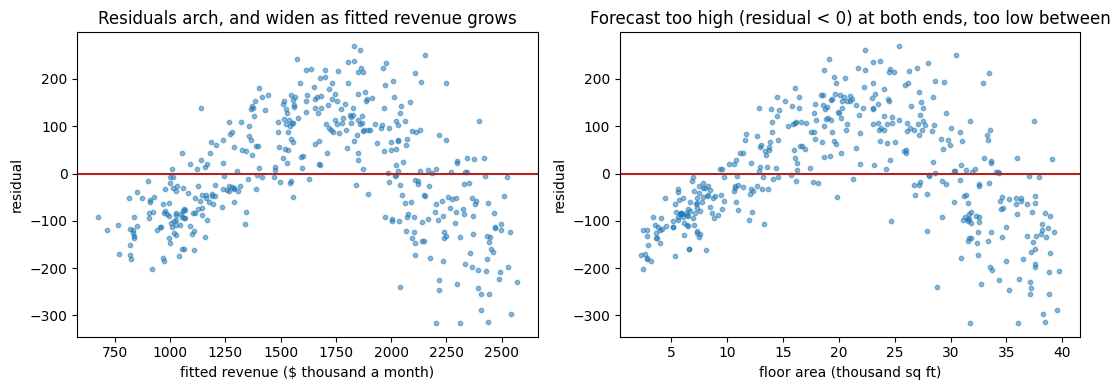

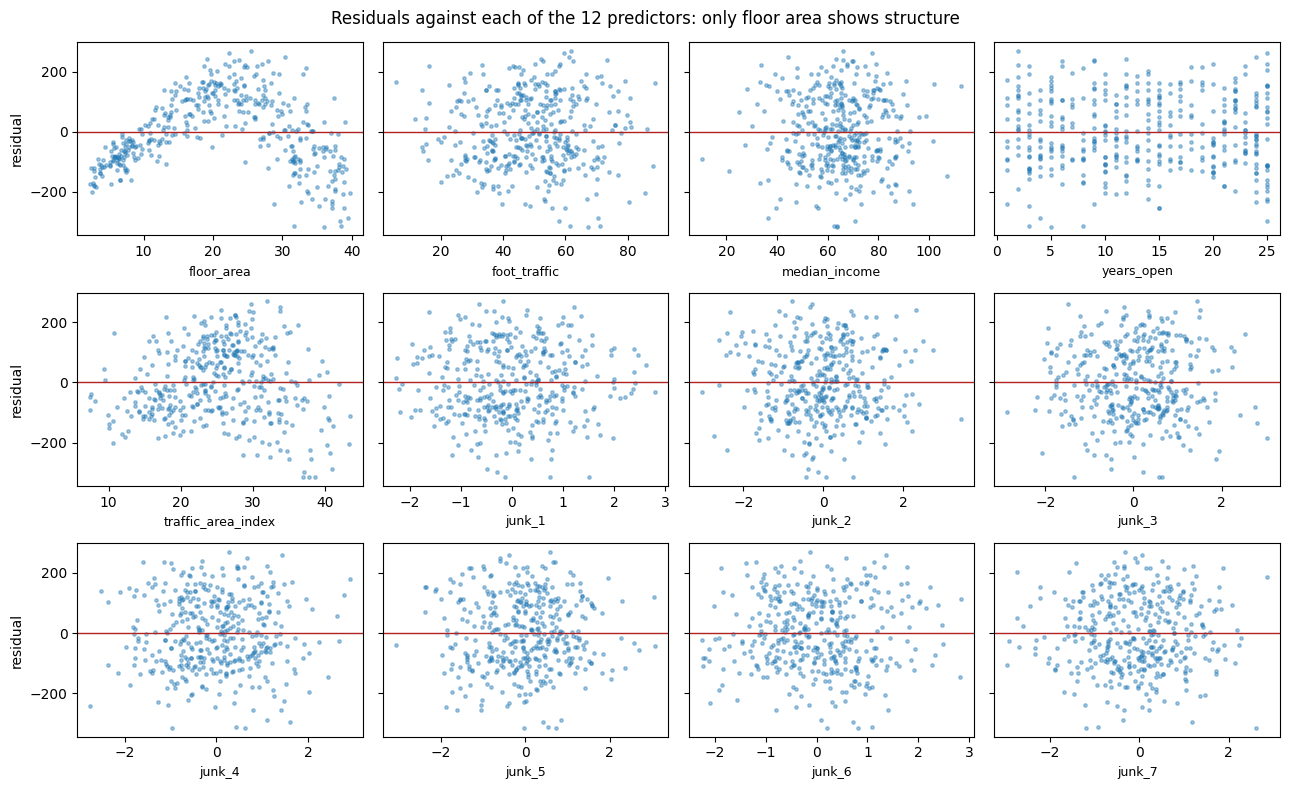

Breusch-Pagan: LM = 42.0, p = 3.3e-05
residual sd by fifth of floor area: {'smallest': 45.4, '2': 70.5, '3': 65.3, '4': 117.2, 'largest': 109.6} -> largest/smallest = 2.4
floor_area coefficient: 46.505 (same under both)
HC3 standard error divided by the classical one, by predictor:
{'floor_area': 1.07, 'foot_traffic': 1.07, 'median_income': 1.05, 'years_open': 1.07, 'traffic_area_index': 1.08, 'junk_1': 0.9, 'junk_2': 1.01, 'junk_3': 1.04, 'junk_4': 1.06, 'junk_5': 0.97, 'junk_6': 1.02, 'junk_7': 0.99}
floor_area: classical 7.679, HC3 8.209
with floor_area squared in the model: Breusch-Pagan LM = 50.5, p = 2.5e-06; residual sd by fifth {'smallest': 41.0, '2': 49.5, '3': 65.7, '4': 100.3, 'largest': 101.7} -> largest/smallest = 2.5


adding floor_area squared: coefficient -0.929, HC3 t = -25.0, R-squared 0.9439 -> 0.9773
floor_area slope: 46.50 in the straight-line model, 88.22 + 2 x -0.929 x floor_area once curvature is allowed
   so the extra revenue per thousand sq ft is 78.9 at 5 th

In [6]:
from statsmodels.stats.diagnostic import het_breuschpagan
resid, fitted = fit_all.resid, fit_all.fittedvalues

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(fitted, resid, s=10, alpha=0.5); ax[0].axhline(0, color="firebrick")
ax[0].set(xlabel="fitted revenue ($ thousand a month)", ylabel="residual", title="Residuals arch, and widen as fitted revenue grows")
ax[1].scatter(stores["floor_area"], resid, s=10, alpha=0.5); ax[1].axhline(0, color="firebrick")
ax[1].set(xlabel="floor area (thousand sq ft)", ylabel="residual", title="Forecast too high (residual < 0) at both ends, too low between")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 4, figsize=(13, 8), sharey=True)
for ax, col in zip(axes.ravel(), stores.columns):
    ax.scatter(stores[col], resid, s=6, alpha=0.4); ax.axhline(0, color="firebrick", lw=1); ax.set_xlabel(col, fontsize=9)
axes[0, 0].set_ylabel("residual"); axes[1, 0].set_ylabel("residual"); axes[2, 0].set_ylabel("residual")
plt.suptitle("Residuals against each of the 12 predictors: only floor area shows structure")
plt.tight_layout(); plt.show()

# (1) non-constant variance
lm, bp_p = het_breuschpagan(resid, X_all)[:2]
fifth = pd.qcut(stores["floor_area"], 5, labels=["smallest", "2", "3", "4", "largest"])
sd_by_fifth = resid.groupby(fifth, observed=True).std()
spread_ratio = sd_by_fifth.iloc[-1] / sd_by_fifth.iloc[0]
fit_hc3 = sm.OLS(revenue, X_all).fit(cov_type="HC3")
print(f"Breusch-Pagan: LM = {lm:.1f}, p = {bp_p:.1e}")
print("residual sd by fifth of floor area:", sd_by_fifth.round(1).to_dict(), f"-> largest/smallest = {spread_ratio:.1f}")
print(f"floor_area coefficient: {fit_all.params['floor_area']:.3f} (same under both)")
se_ratio = (fit_hc3.bse / fit_all.bse).drop("const")
print("HC3 standard error divided by the classical one, by predictor:")
print(se_ratio.round(2).to_dict())
print(f"floor_area: classical {fit_all.bse['floor_area']:.3f}, HC3 {fit_hc3.bse['floor_area']:.3f}")

# (2) a non-linear relationship the model missed: add floor_area squared and see if it matters
X_sq = X_all.assign(floor_area_sq=stores["floor_area"] ** 2)
# the bend itself inflates the residuals of the middle stores, so repeat the variance check with the curve allowed for
fit_sq_c = sm.OLS(revenue, X_sq).fit()
lm_sq, bp_sq = het_breuschpagan(fit_sq_c.resid, X_sq)[:2]
sd_sq = fit_sq_c.resid.groupby(fifth, observed=True).std()
print(f"with floor_area squared in the model: Breusch-Pagan LM = {lm_sq:.1f}, p = {bp_sq:.1e}; "
      f"residual sd by fifth {sd_sq.round(1).to_dict()} -> largest/smallest = {sd_sq.iloc[-1] / sd_sq.iloc[0]:.1f}\n")
fit_sq = sm.OLS(revenue, X_sq).fit(cov_type="HC3")
r2_sq = sm.OLS(revenue, X_sq).fit().rsquared
print(f"\nadding floor_area squared: coefficient {fit_sq.params['floor_area_sq']:.3f}, "
      f"HC3 t = {fit_sq.params['floor_area_sq'] / fit_sq.bse['floor_area_sq']:.1f}, "
      f"R-squared {fit_all.rsquared:.4f} -> {r2_sq:.4f}")
print(f"floor_area slope: {fit_all.params['floor_area']:.2f} in the straight-line model, "
      f"{fit_sq.params['floor_area']:.2f} + 2 x {fit_sq.params['floor_area_sq']:.3f} x floor_area once curvature is allowed")
slope_small = fit_sq.params["floor_area"] + 2 * fit_sq.params["floor_area_sq"] * 5
slope_big = fit_sq.params["floor_area"] + 2 * fit_sq.params["floor_area_sq"] * 40
print(f"   so the extra revenue per thousand sq ft is {slope_small:.1f} at 5 thousand sq ft and {slope_big:.1f} at 40 thousand sq ft")

# (3) influential observations
infl = fit_all.get_influence()
cooks = pd.Series(infl.cooks_distance[0], index=stores.index)
cut = 4 / N_STORES
n_over = int((cooks > cut).sum())
top = cooks.nlargest(10).index
fit_drop = sm.OLS(revenue.drop(index=top), X_all.drop(index=top)).fit()
print(f"\nCook's distance: largest {cooks.max():.3f}; {n_over} stores above 4/n = {cut:.4f}")
print(f"floor_area coefficient without the 10 most influential stores: {fit_drop.params['floor_area']:.3f} "
      f"(full data {fit_all.params['floor_area']:.3f}); classical SE {fit_drop.bse['floor_area']:.3f} (full {fit_all.bse['floor_area']:.3f})")
print(f"the 10 most influential stores have a mean floor area of {stores.loc[top, 'floor_area'].mean():.1f} "
      f"against {stores['floor_area'].mean():.1f} for all stores")

**Two violations clearly present, and a third that is mild.** The left panel above arches, and its spread widens: residuals are tight at low fitted revenue and wide at high. The right panel bends: against floor area the residuals are too low at both ends and too high in between. Against the other eleven predictors the residuals show no structure.

**1. Non-constant variance (assumption: the error has the same spread for every store).** The Breusch-Pagan test rejects it (LM = 42.0, p = 3.3e-05), and the residual standard deviation goes from 45.4 in the smallest fifth of stores to 109.6 in the largest, a ratio of 2.4. The bend itself inflates the residuals of the middle stores, so I repeated the check with floor area squared allowed for: Breusch-Pagan LM = 50.5, p = 2.5e-06, and the residual standard deviation runs from 41.0 to 101.7, a ratio of 2.5. The fan is real, not an artefact of the curve. *Effect on the estimate:* none. The coefficients stay unbiased; the floor-area coefficient is 46.505 under both fits. *Effect on the standard error:* the classical formula assumes one spread for every row, so it is wrong: the HC3 standard error of floor area is 8.209 against 7.679, 1.07 times as large, and across the five real-looking predictors the ratio runs from 1.05 to 1.08. At 400 stores the damage to the standard errors is modest, but it is in the direction that makes the classical errors too small for the predictors that track store size.

**2. A non-linear relationship the model missed (assumption: revenue is a straight line in each predictor, so the error has mean zero at every size).** Adding floor area squared gives a coefficient of -0.929 with an HC3 t of -25.0, and lifts R-squared from 0.9439 to 0.9773. *Effect on the estimate:* it is biased as a description of what an extra thousand sq ft does. The single slope of 46.50 averages a slope that is really 78.9 per thousand sq ft at 5 thousand sq ft and 13.9 at 40, and the straight line over-forecasts at the ends. *Effect on the standard error:* a robust standard error cannot repair this. It gives a correct spread for the wrong quantity; only a better model fixes the bias.

**3. Influential observations (a mild finding).** The largest Cook's distance is 0.020, far below the usual warning level of 1, and 17 stores exceed 4/n = 0.0100. The ten most influential stores are big ones (mean floor area 31.7 against 20.9 overall); dropping them moves the floor-area coefficient from 46.505 to 45.392 and its classical standard error from 7.679 to 7.414. It affects both, a little. It is not the cause of the failure.

### Step 2.2: The over-forecast on big stores (15 pts)

            stores  mean residual  mean revenue  residual as % of revenue
floor_area                                                               
smallest        80          -94.5         895.3                     -10.6
2               80           29.2        1340.1                       2.2
3               80          126.2        1817.0                       6.9
4               80           37.4        2050.4                       1.8
largest         80          -98.3        2239.8                      -4.4

the largest fifth is over-forecast by $98 thousand a store a month, 4.4% of what they earn: $7,862 thousand a month across its 80 stores
   fitted residual at 5 thousand sq ft: -120
   fitted residual at 20 thousand sq ft: +105
   fitted residual at 35 thousand sq ft: -76
   fitted residual at 40 thousand sq ft: -226
   the squared term: -0.899 (t = -23.2); the residuals are not noise around zero but a curve in store size, R-squared 0.575 (58% of the residual variance)


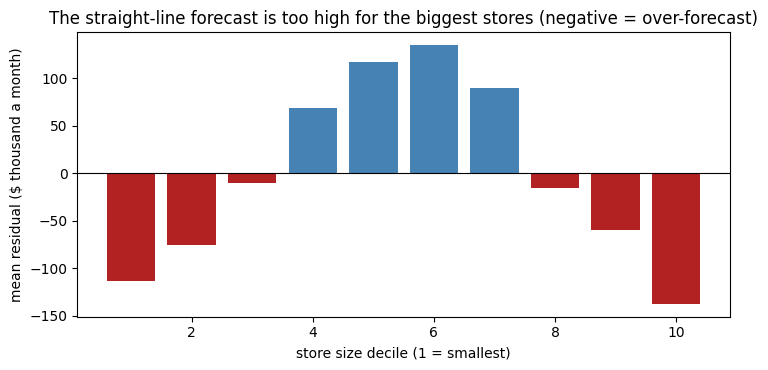


VIF: {'floor_area': 182.0, 'foot_traffic': 129.5, 'median_income': 1.0, 'years_open': 1.0, 'traffic_area_index': 333.1, 'junk_1': 1.0, 'junk_2': 1.1, 'junk_3': 1.0, 'junk_4': 1.0, 'junk_5': 1.0, 'junk_6': 1.0, 'junk_7': 1.0}
R-squared with the index 0.9439, without 0.9439 (change +0.00001)
SE of floor_area: 7.679 with the index, 0.579 without (13.3 times larger)
SE of foot_traffic: 4.603 with the index, 0.409 without (11.2 times larger)
held-out forecast error (RMSE, $ thousand): 123.2 with the index, 123.2 without


In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
fifth = pd.qcut(stores["floor_area"], 5, labels=["smallest", "2", "3", "4", "largest"])
by_fifth = pd.DataFrame({"stores": resid.groupby(fifth, observed=True).size(),
                         "mean residual": resid.groupby(fifth, observed=True).mean(),
                         "mean revenue": revenue.groupby(fifth, observed=True).mean()})
by_fifth["residual as % of revenue"] = 100 * by_fifth["mean residual"] / by_fifth["mean revenue"]
print(by_fifth.round(1).to_string())
over_top = -by_fifth["mean residual"].iloc[-1]
top_pct = -by_fifth["residual as % of revenue"].iloc[-1]
top_total = over_top * by_fifth["stores"].iloc[-1]
print(f"\nthe largest fifth is over-forecast by ${over_top:,.0f} thousand a store a month, {top_pct:.1f}% of what they earn: "
      f"${top_total:,.0f} thousand a month across its {by_fifth['stores'].iloc[-1]} stores")

# the error as a function of size: residual on floor area and its square
curve = sm.OLS(resid, sm.add_constant(pd.DataFrame({"floor_area": stores["floor_area"], "floor_area_sq": stores["floor_area"] ** 2}))).fit()
for a in (5, 20, 35, 40):
    print(f"   fitted residual at {a} thousand sq ft: {curve.params['const'] + curve.params['floor_area'] * a + curve.params['floor_area_sq'] * a * a:+,.0f}")
print(f"   the squared term: {curve.params['floor_area_sq']:.3f} (t = {curve.params['floor_area_sq'] / curve.bse['floor_area_sq']:.1f}); "
      f"the residuals are not noise around zero but a curve in store size, R-squared {curve.rsquared:.3f} "
      f"({curve.rsquared:.0%} of the residual variance)")

decile = pd.qcut(stores["floor_area"], 10, labels=False)
dec = resid.groupby(decile).mean()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(dec.index + 1, dec.values, color=["firebrick" if v < 0 else "steelblue" for v in dec.values])
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="store size decile (1 = smallest)", ylabel="mean residual ($ thousand a month)",
       title="The straight-line forecast is too high for the biggest stores (negative = over-forecast)")
plt.tight_layout(); plt.show()

# Variance inflation factors: one per predictor, from the matrix with the constant
vif = pd.Series({c: variance_inflation_factor(X_all.to_numpy(), i) for i, c in enumerate(X_all.columns) if c != "const"})
print("\nVIF:", vif.round(1).to_dict())

# What a high VIF damages and what it does not: fit with and without the near-duplicate column
no_index = [c for c in stores.columns if c != "traffic_area_index"]
fit_noidx = sm.OLS(revenue, sm.add_constant(stores[no_index])).fit()
Xi_tr, Xi_te = X_tr.drop(columns="traffic_area_index"), X_te.drop(columns="traffic_area_index")
fit_noidx_tr = sm.OLS(y_tr, Xi_tr).fit()
rmse_with = np.sqrt(np.mean((y_te - fit_tr.predict(X_te)) ** 2))
rmse_without = np.sqrt(np.mean((y_te - fit_noidx_tr.predict(Xi_te)) ** 2))
print(f"R-squared with the index {fit_all.rsquared:.4f}, without {fit_noidx.rsquared:.4f} (change {fit_all.rsquared - fit_noidx.rsquared:+.5f})")
print(f"SE of floor_area: {fit_all.bse['floor_area']:.3f} with the index, {fit_noidx.bse['floor_area']:.3f} without "
      f"({fit_all.bse['floor_area'] / fit_noidx.bse['floor_area']:.1f} times larger)")
print(f"SE of foot_traffic: {fit_all.bse['foot_traffic']:.3f} with the index, {fit_noidx.bse['foot_traffic']:.3f} without "
      f"({fit_all.bse['foot_traffic'] / fit_noidx.bse['foot_traffic']:.1f} times larger)")
print(f"held-out forecast error (RMSE, $ thousand): {rmse_with:.1f} with the index, {rmse_without:.1f} without")

**The over-forecast is systematic in store size.** Residuals are actual minus forecast, so a negative mean is an over-forecast. By fifth of floor area the mean residual is -94.5, +29.2, +126.2, +37.4, -98.3 ($ thousand a month), from the smallest to the largest. The largest fifth is over-forecast by $98 thousand per store per month, 4.4% of the $2,240 thousand they earn, which is $7,862 thousand a month across its 80 stores. The smallest fifth is over-forecast too (-10.6% of their revenue, a small amount of money), and the middle stores are under-forecast, up to +126 a store. As a function of size, a curve fitted to the residuals gives -120 at 5 thousand sq ft, +105 at 20, -76 at 35 and -226 at 40: size alone explains 58% of the residual variance, so the residuals are not noise around zero. The cause is in the data-generating process: revenue flattens beyond 22 thousand sq ft and a straight line cannot bend, so it keeps climbing past the stores it should stop at.

**VIF.** The variance inflation factors are 333.1 for `traffic_area_index`, 182.0 for `floor_area` and 129.5 for `foot_traffic`, and about 1 for everything else (the largest of the rest is 1.1). A high VIF says a column is nearly a combination of the others, here the index and the two columns it copies.

*What it damages:* the standard errors of the columns involved. The data cannot say how much revenue belongs to floor area and how much to the index, so those coefficients become imprecise: dropping the index shrinks the standard error of `floor_area` from 7.679 to 0.579 (13.3 times) and that of `foot_traffic` from 4.603 to 0.409 (11.2 times). *What it does not damage:* the fit and the forecasts. R-squared is 0.9439 with the index and 0.9439 without, and the held-out forecast error is 123.2 with it and 123.2 without. Dropping the index because of its VIF would not make the model predict better, and it would not touch the over-forecast of big stores, which has nothing to do with collinearity. Analysts who drop a high-VIF variable to improve accuracy do it for the wrong reason; the only good reason is to read a coefficient.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

                            model  columns  train RMSE  held-out RMSE
                  floor area only        1       143.0          146.6
                   + foot traffic        2       137.5          141.7
            the 4 real predictors        4       123.5          121.3
all 12 predictors (the old model)       12       121.2          123.2
      all 12 + floor area squared       13        77.2           79.3
   all 12 + squares of the 4 real       16        76.9           79.7
 all 12, squares and interactions       90        66.7           90.3
               degree 3 in all 12      454         0.0          438.2

held-out error is lowest for model 5, 'all 12 + floor area squared' (13 columns): RMSE 79.3


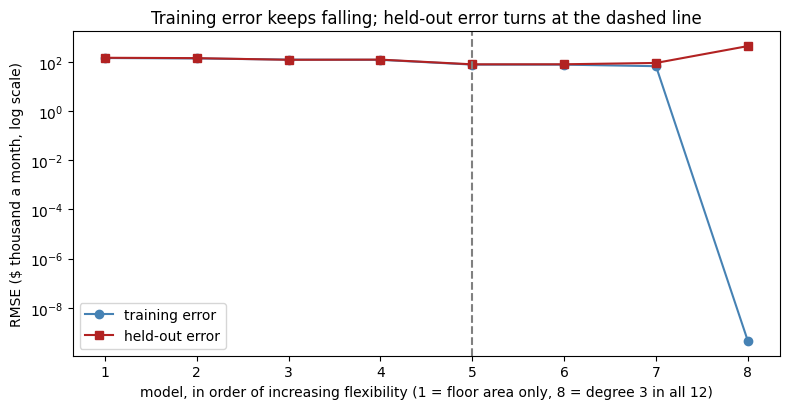

In [14]:
# Step 3.1: the complexity sweep. Same 70/30 split of the stores as Step 1.2.
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

core = ["floor_area", "foot_traffic", "median_income", "years_open"]
every = list(stores.columns)

def squares(df, cols):
    return np.column_stack([df[every].to_numpy()] + [df[c].to_numpy() ** 2 for c in cols])

LADDER = [("floor area only",                    lambda df: df[["floor_area"]].to_numpy()),
          ("+ foot traffic",                     lambda df: df[["floor_area", "foot_traffic"]].to_numpy()),
          ("the 4 real predictors",              lambda df: df[core].to_numpy()),
          ("all 12 predictors (the old model)",  lambda df: df[every].to_numpy()),
          ("all 12 + floor area squared",        lambda df: squares(df, ["floor_area"])),
          ("all 12 + squares of the 4 real",     lambda df: squares(df, core)),
          ("all 12, squares and interactions",   lambda df: PolynomialFeatures(2, include_bias=False).fit_transform(df[every].to_numpy())),
          ("degree 3 in all 12",                 lambda df: PolynomialFeatures(3, include_bias=False).fit_transform(df[every].to_numpy()))]

S_tr, S_te, ys_tr, ys_te = train_test_split(stores, revenue, test_size=0.3, random_state=0)
rows = []
for name, build in LADDER:
    A, B = build(S_tr), build(S_te)
    m = LinearRegression().fit(A, ys_tr)
    rows.append({"model": name, "columns": A.shape[1],
                 "train RMSE": np.sqrt(np.mean((m.predict(A) - ys_tr) ** 2)),
                 "held-out RMSE": np.sqrt(np.mean((m.predict(B) - ys_te) ** 2))})
sweep = pd.DataFrame(rows)
print(sweep.round(1).to_string(index=False))
turn = int(sweep["held-out RMSE"].idxmin())
print(f"\nheld-out error is lowest for model {turn + 1}, '{sweep.loc[turn, 'model']}' "
      f"({sweep.loc[turn, 'columns']} columns): RMSE {sweep.loc[turn, 'held-out RMSE']:.1f}")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(range(1, len(sweep) + 1), sweep["train RMSE"], "o-", label="training error", color="steelblue")
ax.plot(range(1, len(sweep) + 1), sweep["held-out RMSE"], "s-", label="held-out error", color="firebrick")
ax.axvline(turn + 1, ls="--", color="gray")
ax.set_yscale("log"); ax.set_xticks(range(1, len(sweep) + 1))
ax.set_xlabel("model, in order of increasing flexibility (1 = floor area only, 8 = degree 3 in all 12)")
ax.set_ylabel("RMSE ($ thousand a month, log scale)"); ax.legend()
ax.set_title("Training error keeps falling; held-out error turns at the dashed line")
plt.tight_layout(); plt.show()

**Where held-out error turns.** The eight models run from floor area alone to a degree-3 polynomial in all 12 predictors (454 columns). Held-out error is lowest at model 5, the 12 predictors plus floor area squared, at an RMSE of 79.3, and turns up after it.

**Left of the turn: bias.** For models 1 to 4 the training and held-out errors are high and close together (model 4, the old model: 121.2 and 123.2). The model is too simple to follow a revenue curve that flattens, so it is wrong in the same way on every sample, and more of the same predictors does not help. Adding one column, floor area squared, takes the held-out RMSE from 123.2 to 79.3.

**Right of the turn: variance.** Training error keeps falling (77.2, 76.9, 66.7, 1.0) while held-out error rises (79.3, 79.7, 90.3, 432.6). The extra terms fit noise in the 280 training stores, and the fit changes a lot from sample to sample. Model 8 has 454 columns for 280 training stores and fits them almost perfectly, with a training RMSE of 1.0, and is off by 432.6 on new ones. At the turn the held-out RMSE (79.3) is close to the irreducible noise in this simulated world (75.8), so little is left to gain.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [9]:
# Step 3.2: choose by 5-fold cross-validation on all 400 stores, then correct for choosing
from sklearn.model_selection import KFold

def fold_mse(build, df, y, folds):
    """The held-out MSE of one model on each fold."""
    errs = []
    for a, b in folds.split(df):
        A, B = build(df.iloc[a]), build(df.iloc[b])
        m = LinearRegression().fit(A, y.iloc[a])
        errs.append(np.mean((m.predict(B) - y.iloc[b]) ** 2))
    return np.array(errs)

kf = KFold(n_splits=5, shuffle=True, random_state=0)
cv_folds = [fold_mse(build, stores, revenue, kf) for _, build in LADDER]
cv_mse = np.array([e.mean() for e in cv_folds])
best = int(np.argmin(cv_mse))
e = cv_folds[best]
lo, hi = e.mean() - 2 * e.std(ddof=1) / np.sqrt(5), e.mean() + 2 * e.std(ddof=1) / np.sqrt(5)
print(pd.DataFrame({"model": [n for n, _ in LADDER], "CV RMSE": np.sqrt(cv_mse)}).round(1).to_string(index=False))
print(f"\nCV picks model {best + 1}, '{LADDER[best][0]}': RMSE {np.sqrt(e.mean()):.1f}, "
      f"rough interval {np.sqrt(lo):.1f} to {np.sqrt(hi):.1f} ($ thousand a month)")

# Nested CV: choose using only the outer training stores, score on the outer fold the choice never touched
outer = KFold(n_splits=5, shuffle=True, random_state=0)
nested_mse, chosen = [], []
for a, b in outer.split(stores):
    inner = KFold(n_splits=5, shuffle=True, random_state=1)
    pick = int(np.argmin([fold_mse(build, stores.iloc[a], revenue.iloc[a], inner).mean() for _, build in LADDER]))
    m = LinearRegression().fit(LADDER[pick][1](stores.iloc[a]), revenue.iloc[a])
    nested_mse.append(np.mean((m.predict(LADDER[pick][1](stores.iloc[b])) - revenue.iloc[b]) ** 2))
    chosen.append(pick + 1)
nested_mse = np.array(nested_mse)
n_lo = nested_mse.mean() - 2 * nested_mse.std(ddof=1) / np.sqrt(5)
n_hi = nested_mse.mean() + 2 * nested_mse.std(ddof=1) / np.sqrt(5)
print(f"\nnested estimate: RMSE {np.sqrt(nested_mse.mean()):.1f}, rough interval {np.sqrt(n_lo):.1f} to {np.sqrt(n_hi):.1f}; "
      f"outer folds chose models {chosen}")
print(f"best CV score {np.sqrt(cv_mse.min()):.1f} against nested {np.sqrt(nested_mse.mean()):.1f}: "
      f"the optimism from choosing on the same stores is {np.sqrt(nested_mse.mean()) - np.sqrt(cv_mse.min()):+.1f}")
noise_floor = np.sqrt(np.mean(noise_sd ** 2))
print(f"the irreducible noise in this simulated world (root mean noise variance): {noise_floor:.1f}")
mean_rev = revenue.mean()
print(f"nested RMSE as a share of mean revenue ({mean_rev:,.0f}): {100 * np.sqrt(nested_mse.mean()) / mean_rev:.1f}%")

                            model  CV RMSE
                  floor area only    144.4
                   + foot traffic    139.4
            the 4 real predictors    123.7
all 12 predictors (the old model)    124.0
      all 12 + floor area squared     81.6
   all 12 + squares of the 4 real     81.8
 all 12, squares and interactions     91.1
               degree 3 in all 12    429.4

CV picks model 5, 'all 12 + floor area squared': RMSE 81.6, rough interval 76.3 to 86.5 ($ thousand a month)

nested estimate: RMSE 81.7, rough interval 76.7 to 86.5; outer folds chose models [5, 5, 5, 6, 5]
best CV score 81.6 against nested 81.7: the optimism from choosing on the same stores is +0.2
the irreducible noise in this simulated world (root mean noise variance): 75.8
nested RMSE as a share of mean revenue (1,669): 4.9%


**Choosing by cross-validation.** Five-fold cross-validation over all 400 stores picks model 5 as well, with a CV RMSE of 81.6 and a rough interval (mean ± 2 sd / √5) of 76.3 to 86.5 $ thousand a month. The runner-up, model 6, is almost as good (81.8); the other six are clearly worse, and the old 12-predictor model scores 124.0.

**The problem.** The CV score was computed on the same stores I used to choose the model. The best of eight noisy scores is partly the lucky one, so its score is optimistic as a forecast of how the chosen model will do on new stores, and the interval ignores that I chose. The more models are compared, and the closer they are, the worse it gets.

**The fix, implemented.** Nested cross-validation: each outer fold chooses among the eight models using only its own training stores (an inner five-fold search) and scores the winner on the outer fold, which the choice never touched. The nested estimate is an RMSE of 81.7, with a rough interval of 76.7 to 86.5; the outer folds chose models [5, 5, 5, 6, 5]. Against the best CV score the optimism is +0.2, small here because the top two models are nearly tied, so which one wins hardly changes the number, and the rest are far behind.

**What the reported number is and is not.** 81.7 $ thousand a month, 4.9% of mean revenue, is the expected forecast error of a *procedure* (compare these eight models by five-fold cross-validation, take the winner, refit) on new stores drawn like these ones. It is not the error of any one fitted model, and it does not apply to stores outside the 2 to 40 thousand sq ft range or to a different set of months. The interval is rough, with only five folds. No model can do better than the irreducible noise of 75.8.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

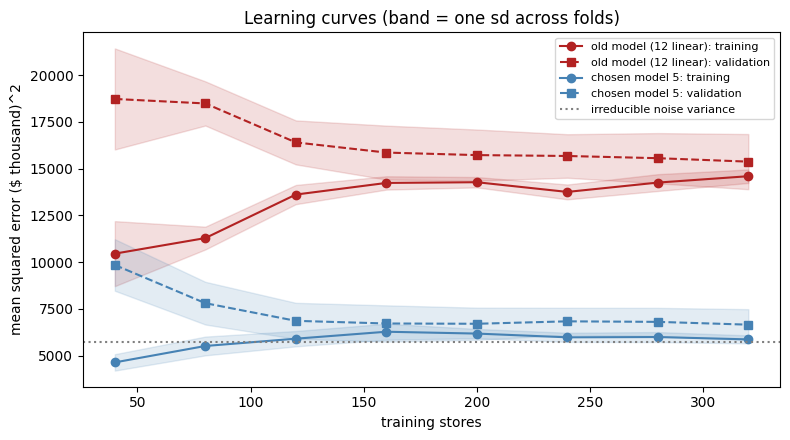

noise variance in this simulated world: 5,738
old model at 320 stores:    training 14,592, validation 15,371, gap 779; validation fell 6.3% from 120 to 320 stores
chosen model at 320 stores: training 5,863, validation 6,651, gap 788; validation fell 3.0% from 120 to 320 stores
old model's validation error above the noise floor at 320 stores: 9,633 (168% more than the noise alone)
chosen model's validation error above the noise floor: 913 (16% more)
validation MSE at 320 stores: old model 15,371, chosen model 6,651: better features cut it by 57%


In [10]:
# Task 4.1: learning curve for the old 12-predictor model (and, for comparison, the model Phase 3 chose)
from sklearn.model_selection import learning_curve

def lc(build, label, ax, color):
    Xb = build(stores)
    sizes, tr, va = learning_curve(LinearRegression(), Xb, revenue, train_sizes=[40, 80, 120, 160, 200, 240, 280, 320],
                                   cv=KFold(5, shuffle=True, random_state=0), scoring="neg_mean_squared_error")
    tr, va = -tr, -va                                     # back to MSE
    ax.plot(sizes, tr.mean(1), "o-", color=color, label=f"{label}: training")
    ax.fill_between(sizes, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), color=color, alpha=0.15)
    ax.plot(sizes, va.mean(1), "s--", color=color, label=f"{label}: validation")
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color=color, alpha=0.15)
    return sizes, tr.mean(1), va.mean(1)

fig, ax = plt.subplots(figsize=(8, 4.5))
sz, tr_old, va_old = lc(LADDER[3][1], "old model (12 linear)", ax, "firebrick")
_, tr_new, va_new = lc(LADDER[best][1], f"chosen model {best + 1}", ax, "steelblue")
ax.axhline(np.mean(noise_sd ** 2), color="gray", ls=":", label="irreducible noise variance")
ax.set(xlabel="training stores", ylabel="mean squared error ($ thousand)^2", title="Learning curves (band = one sd across folds)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

print(f"noise variance in this simulated world: {np.mean(noise_sd ** 2):,.0f}")
print(f"old model at 320 stores:    training {tr_old[-1]:,.0f}, validation {va_old[-1]:,.0f}, gap {va_old[-1] - tr_old[-1]:,.0f}; "
      f"validation fell {100 * (1 - va_old[-1] / va_old[2]):.1f}% from 120 to 320 stores")
print(f"chosen model at 320 stores: training {tr_new[-1]:,.0f}, validation {va_new[-1]:,.0f}, gap {va_new[-1] - tr_new[-1]:,.0f}; "
      f"validation fell {100 * (1 - va_new[-1] / va_new[2]):.1f}% from 120 to 320 stores")
print(f"old model's validation error above the noise floor at 320 stores: {va_old[-1] - np.mean(noise_sd ** 2):,.0f} "
      f"({100 * (va_old[-1] / np.mean(noise_sd ** 2) - 1):.0f}% more than the noise alone)")
print(f"chosen model's validation error above the noise floor: {va_new[-1] - np.mean(noise_sd ** 2):,.0f} "
      f"({100 * (va_new[-1] / np.mean(noise_sd ** 2) - 1):.0f}% more)")
print(f"validation MSE at 320 stores: old model {va_old[-1]:,.0f}, chosen model {va_new[-1]:,.0f}: "
      f"better features cut it by {100 * (1 - va_new[-1] / va_old[-1]):.0f}%")

**The learning curve agrees with my Phase 3 diagnosis.** For the old 12-predictor model the two curves have converged at a high level: at 320 training stores the training MSE is 14,592 and the validation MSE 15,371, a gap of only 779. A small gap says the model is not fitting noise (not high variance). A high level says it is missing structure: 15,371 is 168% above the irreducible noise variance of 5,738, which I know because I simulated it. That is high bias. Validation error fell only 6.3% between 120 and 320 stores, so more stores would not help.

For the model Phase 3 chose (floor area squared added) both curves sit near the noise floor: validation MSE 6,651, only 16% above it, gap 788, and nearly flat as stores are added. Better features were the higher-return investment: one extra column cut validation MSE from 15,371 to 6,651, 57%, while nearly tripling the stores moved the old model's error by 6.3%.

Phase 3 reached the same verdict by a different route: the old model sat to the left of the turn (bias), and a single curvature term moved it to the turn. The two do not disagree. One caution: reading "the level" requires knowing the noise floor, which on real data I would not know. The learning curve alone would show a flat, high plateau without telling me how much of it is bias and how much is noise; the sweep, which adds features and watches held-out error, is what shows it.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [11]:
X = rng.normal(size=(N_STORES, 300)); y = revenue.to_numpy()      # the demonstration: 300 columns of pure noise, Phase 1 revenue as y
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.10


In [12]:
# (b) the same three steps inside a Pipeline, so each is refitted on every fold's training stores
from sklearn.pipeline import Pipeline
leaky_r2 = scores.mean()
pipe = Pipeline([("scale", StandardScaler()), ("select", SelectKBest(f_regression, k=20)), ("ols", LinearRegression())])
pipe_r2 = cross_val_score(pipe, X, y, cv=5, scoring="r2").mean()
print(f"analyst's cell (selected on all rows) : {leaky_r2:+.3f}")
print(f"the same steps inside a Pipeline      : {pipe_r2:+.3f}")
print(f"gap (inflation)                       : {leaky_r2 - pipe_r2:+.3f}")

# (a) the scaling decoy: does fitting the scaler on all rows change anything for OLS with an intercept?
plain = cross_val_score(LinearRegression(), stores, revenue, cv=5, scoring="r2")
scaled_all = cross_val_score(LinearRegression(), StandardScaler().fit_transform(stores), revenue, cv=5, scoring="r2")
print(f"\nreal predictors, cross-validated R^2: unscaled {plain.mean():.6f}, scaled on all rows {scaled_all.mean():.6f}, "
      f"largest difference in any fold {np.max(np.abs(plain - scaled_all)):.1e}")

# and the same question on the noise: select with real predictors present, to see why the brief used noise only
real_plus = np.column_stack([stores.to_numpy(), X])
leak_real = cross_val_score(LinearRegression(), SelectKBest(f_regression, k=20).fit_transform(StandardScaler().fit_transform(real_plus), y), y, cv=5, scoring="r2").mean()
pipe_real = cross_val_score(pipe, real_plus, y, cv=5, scoring="r2").mean()
print(f"with the real predictors in X too: leaky {leak_real:.3f}, Pipeline {pipe_real:.3f}, gap {leak_real - pipe_real:+.3f}")

analyst's cell (selected on all rows) : +0.096
the same steps inside a Pipeline      : -0.260
gap (inflation)                       : +0.356

real predictors, cross-validated R^2: unscaled 0.939512, scaled on all rows 0.939512, largest difference in any fold 1.1e-16
with the real predictors in X too: leaky 0.920, Pipeline 0.925, gap -0.004


**(a) Which step leaks.** `SelectKBest(f_regression, k=20)` is the step that inflates the score. It looks at `y` and at every row, including the rows that cross-validation will later hold out, to pick the 20 columns most correlated with revenue. The held-out rows therefore helped build the model that is scored on them. `StandardScaler` is harmless for OLS with an intercept: it only shifts and rescales each column, which leaves the span of the columns unchanged (the intercept absorbs a shift and each coefficient absorbs a rescale), so the fitted values are identical whether the scaler is fitted on all rows or on a fold. The check on the real predictors shows it: cross-validated R-squared 0.939512 unscaled and 0.939512 scaled on all rows, with a largest difference of 1e-16 in any fold.

**(b) The demonstration.** With 300 columns of pure noise as `X` and the Phase 1 revenue as `y`, none of which predicts revenue, the analyst's cell prints a "validated R^2" of +0.10: it claims to explain about a tenth of revenue from nothing. The same three steps inside a `Pipeline`, refitted on each fold's training stores, give -0.260, below zero, as an honest score for a model with no information should be (worse than predicting the average). The gap, the inflation, is +0.356. With the real predictors in `X` as well, the leaky cell scores 0.920 and the Pipeline 0.925, a gap of -0.004, because selection picks the real columns either way; that is why the demonstration uses noise only.

**(c)** It is a special case of the Step 3.2 problem: in both, rows that were supposed to be unseen took part in a choice (which columns here, which model there), so the score that follows is optimistic.

### Task 4.3: The handover note (3 pts)

**Handover note: the store revenue model**

**What it predicts.** Monthly revenue by store, in $ thousand, from floor area, foot traffic, local income and years open. Use the version with floor area squared; retire the 12-column straight-line model. The index and the seven junk columns add nothing.

**Honest expected error.** About 82 $ thousand a month per store (nested cross-validation RMSE 81.7, rough interval 76.7 to 86.5), 4.9% of mean revenue; roughly 76 of that is noise nobody can remove. The old note's R-squared of 0.94 was true in and out of sample and said nothing about this: the old model's RMSE was 123.2, and it over-forecast the largest fifth of stores by $98 thousand each, every month.

**It will fail when:** (1) a store is larger than any in the data, above about 40 thousand sq ft: revenue flattens with size, so extrapolating a straight line over-forecasts; (2) one error figure is quoted for every store: the spread is 2.4 times wider for the biggest stores than the smallest, so their forecasts need wider intervals.

**Build next.** A model whose curve bends and whose spread grows with size (log revenue, or weights), chosen by nested cross-validation, rerun monthly, with the mean error tracked by size fifth so drift shows early.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

*Model and date: GPT-6, 11/18/26*

*Prompt: [Prep] Act as a machine learning engineer who diagnoses model
performance problems in production.

[Request] I have a store-level revenue regression with 400 rows and
about 12 predictors. Write Python that produces a learning curve --
training and validation error as a function of training set size --
and interprets it to distinguish a high-bias problem from a
high-variance one.

[Iterate] scikit-learn, numpy and matplotlib. Reuse my X and y. Plot
both curves on one axis with a shaded band for variability across
folds.

[Mechanism Check] Add comments explaining what the GAP between the two
curves indicates versus what the LEVEL both converge to indicates, and
what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better
features is the higher-return investment.*

*Reply:*

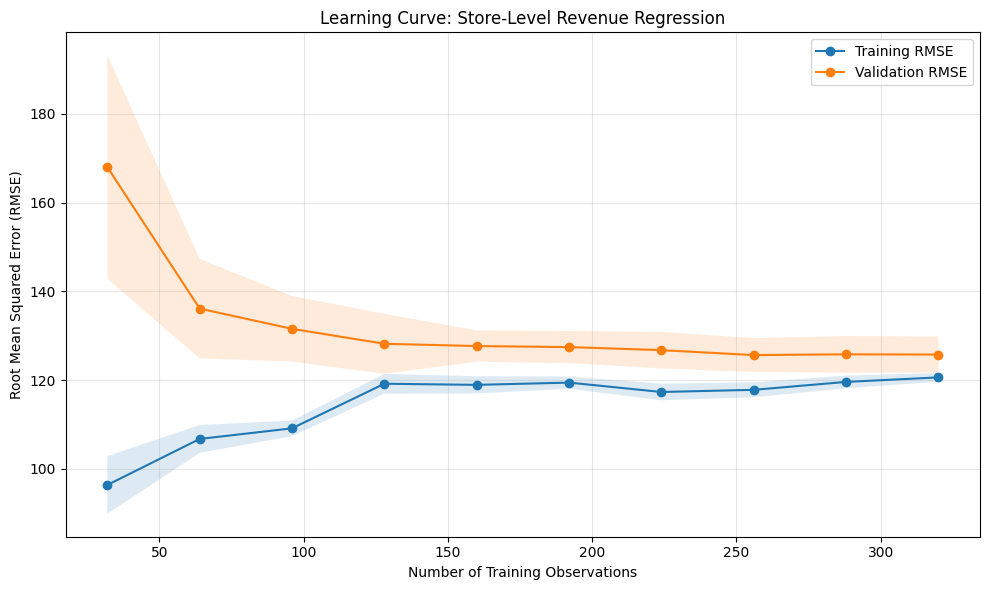

In [13]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import learning_curve, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

# Use your existing X and y
X, y = stores, revenue            # CHANGED: the reply assumed X and y exist; here they are the Phase 1 stores and revenue
# Baseline model: replace this with your production estimator if applicable
model = LinearRegression()        # CHANGED: the production model is the inherited straight-line regression, not a random forest

# Five-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Calculate learning curves
train_sizes, train_scores, validation_scores = learning_curve(
    estimator=model,
    X=X,
    y=y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Convert negative RMSE scores into positive RMSE
train_scores = -train_scores
validation_scores = -validation_scores

# Calculate average error and variability across folds
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)

validation_mean = np.mean(validation_scores, axis=1)
validation_std = np.std(validation_scores, axis=1)

# Plot both learning curves
plt.figure(figsize=(10, 6))

plt.plot(
    train_sizes, train_mean,
    marker="o", label="Training RMSE"
)

plt.plot(
    train_sizes, validation_mean,
    marker="o", label="Validation RMSE"
)

# Shaded bands show variability across folds
plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.fill_between(
    train_sizes,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.15
)

plt.xlabel("Number of Training Observations")
plt.ylabel("Root Mean Squared Error (RMSE)")
plt.title("Learning Curve: Store-Level Revenue Regression")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

*One line on each change I made to its code:*

1. `X, y = stores, revenue`: the reply assumed `X` and `y` already exist; here they are the Phase 1 stores and revenue.
2. `model = LinearRegression()` in place of the `RandomForestRegressor`: the production model is the inherited straight-line regression.
3. Added `from sklearn.linear_model import LinearRegression` for change 2.
4. Added a second cell that repeats the curve for the old model, the Phase 3 choice and the reply's forest, and prints the numbers behind the plot and the irreducible noise.
5. Wrote the reading of the gap and the level myself (the reply's code had no comments about them and gave no verdict on stores versus features).

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.